# 1. Data Cleaning — Craigslist used vehicles

**Goal:** turn the raw `vehicles.csv` (426,880 rows, 26 columns) into a clean table that the modelling notebook can use to predict `price`.

**Plan:**
1. Load and inspect the data.
2. Drop columns that cannot help or are unusable.
3. Remove impossible / placeholder values (price, year, odometer, coordinates).
4. Engineer simple features (vehicle age, cylinders as a number, model grouping).
5. Handle missing values in a way that keeps the information (missing = its own category).
6. Remove duplicate listings.
7. Save the cleaned table and a short report.

Every decision is explained in the cell that makes it.

## 1. Imports and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')

RAW_PATH = 'vehicles.csv'
OUT_PATH = 'vehicles_clean.csv.gz'

# Read everything with default types first; the file is ~1.4 GB but fits in RAM (17 GB).
raw = pd.read_csv(RAW_PATH, low_memory=False)
print('Shape:', raw.shape)
report = [('raw', len(raw))]
raw.head(3)

Shape: (426880, 26)


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN


**What this does:** loads the CSV into a DataFrame and keeps a copy of the row count so we can report how many rows each step removes.

## 2. Missing values overview

In [2]:
missing_pct = (raw.isna().mean() * 100).sort_values(ascending=False)
missing_pct.to_frame('missing_%').round(1)

,missing_%
county,100.00
size,71.80
cylinders,41.60
condition,40.80
VIN,37.70
drive,30.60
paint_color,30.50
type,21.80
manufacturer,4.10
title_status,1.90


**What this does:** shows how much of each column is empty.

**Why:** a column that is almost entirely empty (e.g. `county`, 100% missing) carries no usable signal. Columns with 20–70% missing are kept, but their blanks are treated as a category rather than dropped (see section 6).

## 3. Drop unusable columns

In [3]:
drop_cols = {
    'id': 'row identifier, no predictive meaning',
    'url': 'long text link, unique per listing',
    'region_url': 'link, duplicates the region name',
    'image_url': 'link to a photo, not used',
    'county': '100% missing',
    'VIN': '38% missing and unique per car; cannot generalise to new cars',
    'posting_date': 'only spans ~2 months (Apr-Jun 2021); used only for a sanity check here',
    'description': 'free text; needs NLP, out of scope for these two model families',
    'region': '~400 values that overlap with state + lat/long',
}
df = raw.drop(columns=list(drop_cols))
pd.Series(drop_cols).to_frame('reason')

,reason
id,"row identifier, no predictive meaning"
url,"long text link, unique per listing"
region_url,"link, duplicates the region name"
image_url,"link to a photo, not used"
county,100% missing
VIN,38% missing and unique per car; cannot general...
posting_date,only spans ~2 months (Apr-Jun 2021); used only...
description,"free text; needs NLP, out of scope for these t..."
region,~400 values that overlap with state + lat/long


**What this does:** removes columns we will not use and records why.

**Why:** identifiers and links leak nothing useful, `county` is empty, and `VIN`/`description` need special processing (VIN decoding or text models) that is beyond the linear and tree models requested. `region` is redundant with `state` and the coordinates.

## 4. Target: remove placeholder and impossible prices

In [4]:
print('Price == 0 rows:', (df.price == 0).sum())
print('Price < 500:', (df.price < 500).sum())
print('Price > 150,000:', (df.price > 150_000).sum())

df = df[(df.price >= 500) & (df.price <= 150_000)].copy()
report.append(('price in [500, 150000]', len(df)))
print('After price filter:', len(df))

Price == 0 rows: 32895
Price < 500: 42094
Price > 150,000: 196


After price filter: 384590


**What this does:** keeps prices between $500 and $150,000.

**Why:** a price of 0 (about 33k rows) is a "call for price" placeholder, not a real price. Very low prices are mostly parts or scrap. Prices above $150k are extremely rare used-car listings (under 0.1%) that would dominate squared-error metrics. The target is log-transformed later in modelling, which is why the bounds are kept simple here.

## 5. Year and odometer

In [5]:
print('Year < 1980:', (df.year < 1980).sum(), '| year missing:', df.year.isna().sum())
print('Odometer < 100:', (df.odometer < 100).sum(), '| > 500,000:', (df.odometer > 500_000).sum(),
      '| missing:', df.odometer.isna().sum())

df = df[(df.year.isna()) | (df.year >= 1980)].copy()
df = df[(df.odometer.isna()) | ((df.odometer >= 100) & (df.odometer <= 500_000))].copy()
report.append(('year >= 1980 and odometer in [100, 500k]', len(df)))

# Vehicle age is more linear than raw year. Data is from 2021 but the newest model year is 2022.
df['age'] = 2022 - df['year']
df = df.drop(columns='year')
print('After year/odometer filter:', len(df))
df[['age', 'odometer']].describe().T

Year < 1980: 7997 | year missing: 1173
Odometer < 100: 4562 | > 500,000: 1148 | missing: 2119
After year/odometer filter: 371706


,count,mean,std,min,25%,50%,75%,max
age,"370,655.00",10.01,6.37,0.00,5.00,9.00,14.00,42.00
odometer,"369,607.00","94,674.68","63,918.44",100.00,"40,003.00","89,500.00","137,131.50","500,000.00"


**What this does:** removes cars older than 1980, and odometer readings under 100 or over 500,000 miles. Then replaces `year` with `age = 2022 - year`.

**Why:** odometer = 0 on a used car is almost always "not entered", and values over 500k are typing errors. Age is a more direct measure of depreciation than the year, and the linear model can use it as a simple number.

## 6. Coordinates

In [6]:
outside = ((df.lat < 18) | (df.lat > 72) | (df.long > -60) | (df.long < -170))
print('Coordinates outside the US bounding box:', outside.sum())
df.loc[outside, ['lat', 'long']] = np.nan
print('Coordinates missing now:', df.lat.isna().sum())

Coordinates outside the US bounding box: 86
Coordinates missing now: 3390


**What this does:** sets coordinates outside the USA's rough bounding box to missing.

**Why:** a few listings have wrong lat/long (e.g. swapped or zero). They are blanked rather than dropping the whole row; the modelling notebook will impute them.

## 7. Cylinders and fuel: turn text into numbers or categories

In [7]:
print(df.cylinders.value_counts(dropna=False))
df['cylinders'] = pd.to_numeric(df.cylinders.str.extract(r'(\d+)')[0], errors='coerce')
print('\ncylinders after parsing:')
print(df.cylinders.value_counts(dropna=False).sort_index())

cylinders
NaN             151810
6 cylinders      85088
4 cylinders      68966
8 cylinders      61454
5 cylinders       1626
10 cylinders      1140
other              900
3 cylinders        546
12 cylinders       176
Name: count, dtype: int64



cylinders after parsing:
cylinders
3.00        546
4.00      68966
5.00       1626
6.00      85088
8.00      61454
10.00      1140
12.00       176
NaN      152710
Name: count, dtype: int64


**What this does:** turns `"6 cylinders"` into the number `6`. Values like `"other"` become missing.

**Why:** cylinder count has a natural order (more cylinders = bigger engine), which a numeric column expresses better than a text label.

## 8. Manufacturer and model: group rare values

In [8]:
df['manufacturer'] = df.manufacturer.str.lower().str.strip()
df['model'] = df.model.str.lower().str.strip()

top_models = df.model.value_counts().head(150).index
print('Distinct models before grouping:', df.model.nunique(dropna=True))
print('Share of rows covered by top 150 models:', round(df.model.isin(top_models).mean(), 3))

df['model'] = np.where(df.model.isin(top_models), df.model, 'other')
df.loc[df.model.isna(), 'model'] = 'missing'
report.append(('model grouped to top 150 + other', len(df)))
print('Distinct models after grouping:', df.model.nunique())

Distinct models before grouping: 24334
Share of rows covered by top 150 models: 0.397
Distinct models after grouping: 151


**What this does:** lowercases and trims names, keeps the 150 most common models, and groups the rest as `other`.

**Why:** there are about 28k distinct model names. One-hot encoding them all would create huge, mostly empty columns that hurt the linear model and slow training. The top 150 still cover about 40% of listings, so this keeps the most common models while limiting column count.

## 9. Missing categories: keep them as their own value

In [9]:
cat_cols = ['manufacturer', 'condition', 'fuel', 'title_status', 'transmission',
            'drive', 'size', 'type', 'paint_color', 'state']
for c in cat_cols:
    df[c] = df[c].fillna('missing').str.lower().str.strip()

print(df[cat_cols].nunique())

manufacturer    43
condition        7
fuel             6
title_status     6
transmission     4
drive            4
size             5
type            14
paint_color     13
state           51
dtype: int64


**What this does:** replaces blanks in categorical columns with the label `missing`.

**Why:** many blanks are informative. For example, `size` is missing for 72% of rows, and whether a seller filled it in says something about the listing. Dropping these rows would throw away most of the data; imputing with the mode would hide the fact that the value was not given.

## 10. Remove duplicate listings

In [10]:
key_cols = ['price', 'age', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel',
            'odometer', 'title_status', 'transmission', 'drive', 'size', 'type',
            'paint_color', 'state', 'lat', 'long']
before = len(df)
df = df.drop_duplicates(subset=key_cols).copy()
print(f'Removed {before - len(df):,} duplicate listings')
report.append(('duplicates removed', len(df)))

Removed 80,564 duplicate listings

**What this does:** keeps one row for each identical set of car attributes.

**Why:** Craigslist users repost the same car many times in one area. Duplicates would count the same car several times, making the model look better on the test set than it really is (the same car could appear in both train and test). `id`, `url` and `posting_date` were left out of the key on purpose, because they differ between reposts.

## 11. Final checks and save

In [11]:
print('Rows:', len(df), '| columns:', df.shape[1])
print('Remaining missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])

print('\nPrice summary after cleaning:')
print(df.price.describe(percentiles=[.01, .5, .99]))

report_df = pd.DataFrame(report, columns=['step', 'rows_remaining'])
report_df['rows_removed_by_step'] = -report_df.rows_remaining.diff().fillna(0).astype(int)
display(report_df)

df.to_csv(OUT_PATH, index=False, compression='gzip')
print('Saved to', OUT_PATH)

Rows: 291142 | columns: 17
Remaining missing values per column:
cylinders    115554
odometer       1182
lat            1813
long           1813
age             774
dtype: int64

Price summary after cleaning:
count   291,142.00
mean     18,945.06
std      14,387.17
min         500.00
1%        1,000.00
50%      15,888.00
99%      64,990.00
max     150,000.00
Name: price, dtype: float64


,step,rows_remaining,rows_removed_by_step
0,raw,426880,0
1,"price in [500, 150000]",384590,42290
2,"year >= 1980 and odometer in [100, 500k]",371706,12884
3,model grouped to top 150 + other,371706,0
4,duplicates removed,291142,80564


Saved to vehicles_clean.csv.gz


**What this does:** prints the final shape and a per-step row count, then saves the cleaned table as a compressed CSV.

**Why:** the modelling notebook reads this file, so cleaning is run once and every model uses exactly the same data.

## 12. Quick visual check

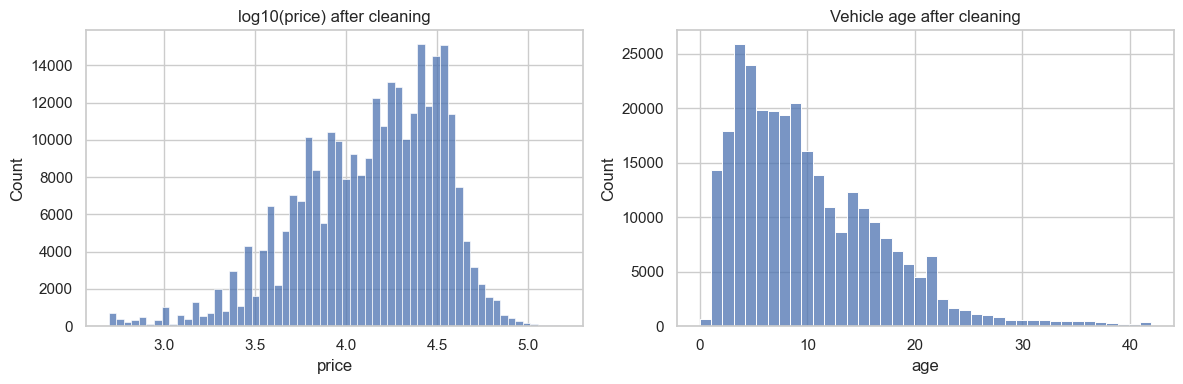

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log10(df.price), bins=60, ax=axes[0])
axes[0].set_title('log10(price) after cleaning')
sns.histplot(df.age, bins=40, ax=axes[1])
axes[1].set_title('Vehicle age after cleaning')
plt.tight_layout(); plt.show()

**What this does:** plots the target and the new age feature.

**Why:** a quick look confirms the distributions are sensible before modelling. The price is heavily right-skewed in raw form, which is why the modelling notebook will use log(price).